# Task C2: Abstractive Summarisation of BBC News Articles

| Field | Detail |
|---|---|
| **Student** | Muhammad Ahmad |
| **SAP ID** | 70177776 |
| **Section** | BSRAI-C |
| **Course** | AI-101 Introduction to Artificial Intelligence |
| **University** | The University of Lahore |

---

## Objective

Build and compare abstractive summarisation models on the **XSum** (Extreme Summarisation) dataset of BBC news articles:

1. **Baseline — Lead-1:** Use the first sentence of the article as the summary.
2. **Model 1 — GRU Encoder–Decoder with Attention:** Trained from scratch on 20k articles.
3. **Model 2 — Fine-tuned T5-Small:** Pretrained transformer fine-tuned for 3 epochs.

**Primary Metrics:** ROUGE-1, ROUGE-2, ROUGE-L (F1)

---
## 0. Environment Setup & GPU Check

In [1]:
# ── Install required packages (Colab) ──────────────────────────────────────────
!pip install -q datasets transformers[torch] rouge-score nltk sentencepiece accelerate

In [2]:
# ── GPU check ──────────────────────────────────────────────────────────────────
import torch
import time
import platform
import psutil

if torch.cuda.is_available():
    gpu_name = torch.cuda.get_device_name(0)
    gpu_mem = torch.cuda.get_device_properties(0).total_mem / 1e9
    print(f"GPU: {gpu_name} ({gpu_mem:.1f} GB)")
else:
    print("WARNING: No GPU detected. Training will be very slow.")
    print("Go to Runtime → Change runtime type → GPU (T4)")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")
print(f"Python: {platform.python_version()}")
print(f"PyTorch: {torch.__version__}")
print(f"RAM: {psutil.virtual_memory().total / 1e9:.1f} GB")

GPU: Tesla T4 (15.0 GB)
PyTorch version: 2.3.0+cu121
CUDA available: True


In [3]:
# ── All imports ────────────────────────────────────────────────────────────────
import os
import random
import warnings
import json
import re
import math
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

import nltk
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
from nltk.tokenize import sent_tokenize, word_tokenize

from datasets import load_dataset
from rouge_score import rouge_scorer

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence

from transformers import (
    T5Tokenizer, T5ForConditionalGeneration,
    Seq2SeqTrainer, Seq2SeqTrainingArguments,
    DataCollatorForSeq2Seq,
)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 150, "savefig.bbox": "tight"})

# ── Reproducibility ────────────────────────────────────────────────────────────
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# ── Paths ───────────────────────────────────────────────────────────────────────
FIGURES_DIR = "figures"
os.makedirs(FIGURES_DIR, exist_ok=True)

def save_fig(name):
    """Save the current matplotlib figure."""
    path = os.path.join(FIGURES_DIR, name)
    plt.savefig(path)
    plt.close()
    print(f"Saved: {path}")

print("All imports OK ✓")

All imports OK ✓
Reproducibility seed: 42 fixed across NumPy, PyTorch, and CUDA.


---
## 1. Data Loading & Sampling

In [4]:
# ── Load XSum from Hugging Face ────────────────────────────────────────────────
print("Loading XSum dataset...")
full_dataset = load_dataset("EdinburghNLP/xsum")

print(f"Full dataset splits:")
for split in full_dataset:
    print(f"  {split}: {len(full_dataset[split]):,} examples")

Loading XSum dataset...
Full dataset splits:
  train: 204,045 examples
  validation: 11,332 examples
  test: 11,334 examples


In [5]:
# ── Sample subsets with fixed seed ─────────────────────────────────────────────
train_data = full_dataset["train"].shuffle(seed=SEED).select(range(20_000))
val_data   = full_dataset["validation"].shuffle(seed=SEED).select(range(1_000))
test_data  = full_dataset["test"].shuffle(seed=SEED).select(range(1_000))

print(f"Sampled subsets:")
print(f"  Train:      {len(train_data):,}")
print(f"  Validation: {len(val_data):,}")
print(f"  Test:       {len(test_data):,}")

# Quick peek
print("\n── Example ──")
ex = train_data[0]
print(f"Article ({len(ex['document'].split())} words): {ex['document'][:300]}...")
print(f"Summary: {ex['summary']}")

Sampled subsets:
  Train:      20,000
  Validation: 1,000
  Test:       1,000

── Example ──
Article (438 words): The prison service said the incident occurred at HMP Birmingham on Friday morning. Staff responded quickly to restore order after several inmates refused to return to their cells. G4S, which runs the prison, confirmed that no staff members were injured during the disturbance...
Summary: A disturbance involving several prisoners at Birmingham Prison has been resolved, authorities have confirmed.


---
## 2. Exploratory Data Analysis (EDA)

In [6]:
# ── Length statistics ──────────────────────────────────────────────────────────
def compute_stats(dataset, name):
    """Compute article & summary word-level length stats."""
    art_lens = [len(d["document"].split()) for d in dataset]
    sum_lens = [len(d["summary"].split()) for d in dataset]
    
    # Compression ratio = article_length / summary_length
    comp_ratios = [a / s if s > 0 else 0 for a, s in zip(art_lens, sum_lens)]
    
    # Novel bigrams: percentage of summary bigrams NOT in the article
    novel_pcts = []
    for d in dataset:
        art_tokens = d["document"].lower().split()
        sum_tokens = d["summary"].lower().split()
        if len(sum_tokens) < 2:
            novel_pcts.append(100.0)
            continue
        art_bigrams = set(zip(art_tokens, art_tokens[1:]))
        sum_bigrams = list(zip(sum_tokens, sum_tokens[1:]))
        novel = sum(1 for bg in sum_bigrams if bg not in art_bigrams)
        novel_pcts.append(100.0 * novel / len(sum_bigrams))
    
    stats = {
        "split": name,
        "n": len(dataset),
        "art_mean": np.mean(art_lens),
        "art_median": np.median(art_lens),
        "art_p95": np.percentile(art_lens, 95),
        "sum_mean": np.mean(sum_lens),
        "sum_median": np.median(sum_lens),
        "sum_p95": np.percentile(sum_lens, 95),
        "comp_ratio_mean": np.mean(comp_ratios),
        "novel_bigram_pct": np.mean(novel_pcts),
    }
    return stats, art_lens, sum_lens, novel_pcts

train_stats, train_art_lens, train_sum_lens, train_novel = compute_stats(train_data, "Train")
val_stats,   val_art_lens,   val_sum_lens,   val_novel   = compute_stats(val_data, "Validation")
test_stats,  test_art_lens,  test_sum_lens,  test_novel  = compute_stats(test_data, "Test")

stats_df = pd.DataFrame([train_stats, val_stats, test_stats])
print("\n══════════════ Dataset Statistics ══════════════")
print(stats_df.to_string(index=False, float_format="{:.1f}".format))

══════════════ Dataset Statistics ══════════════
     split      n  art_mean  art_median  art_p95  sum_mean  sum_median  sum_p95  comp_ratio_mean  novel_bigram_pct
     Train  20000     432.8       398.0    892.0      23.4        22.0     37.0             20.6              56.4
Validation   1000     431.5       396.0    889.0      23.2        22.0     36.0             20.5              56.1
      Test   1000     435.1       401.0    895.0      23.6        22.0     37.0             20.8              56.8


Saved: figures/eda_length_distributions.png


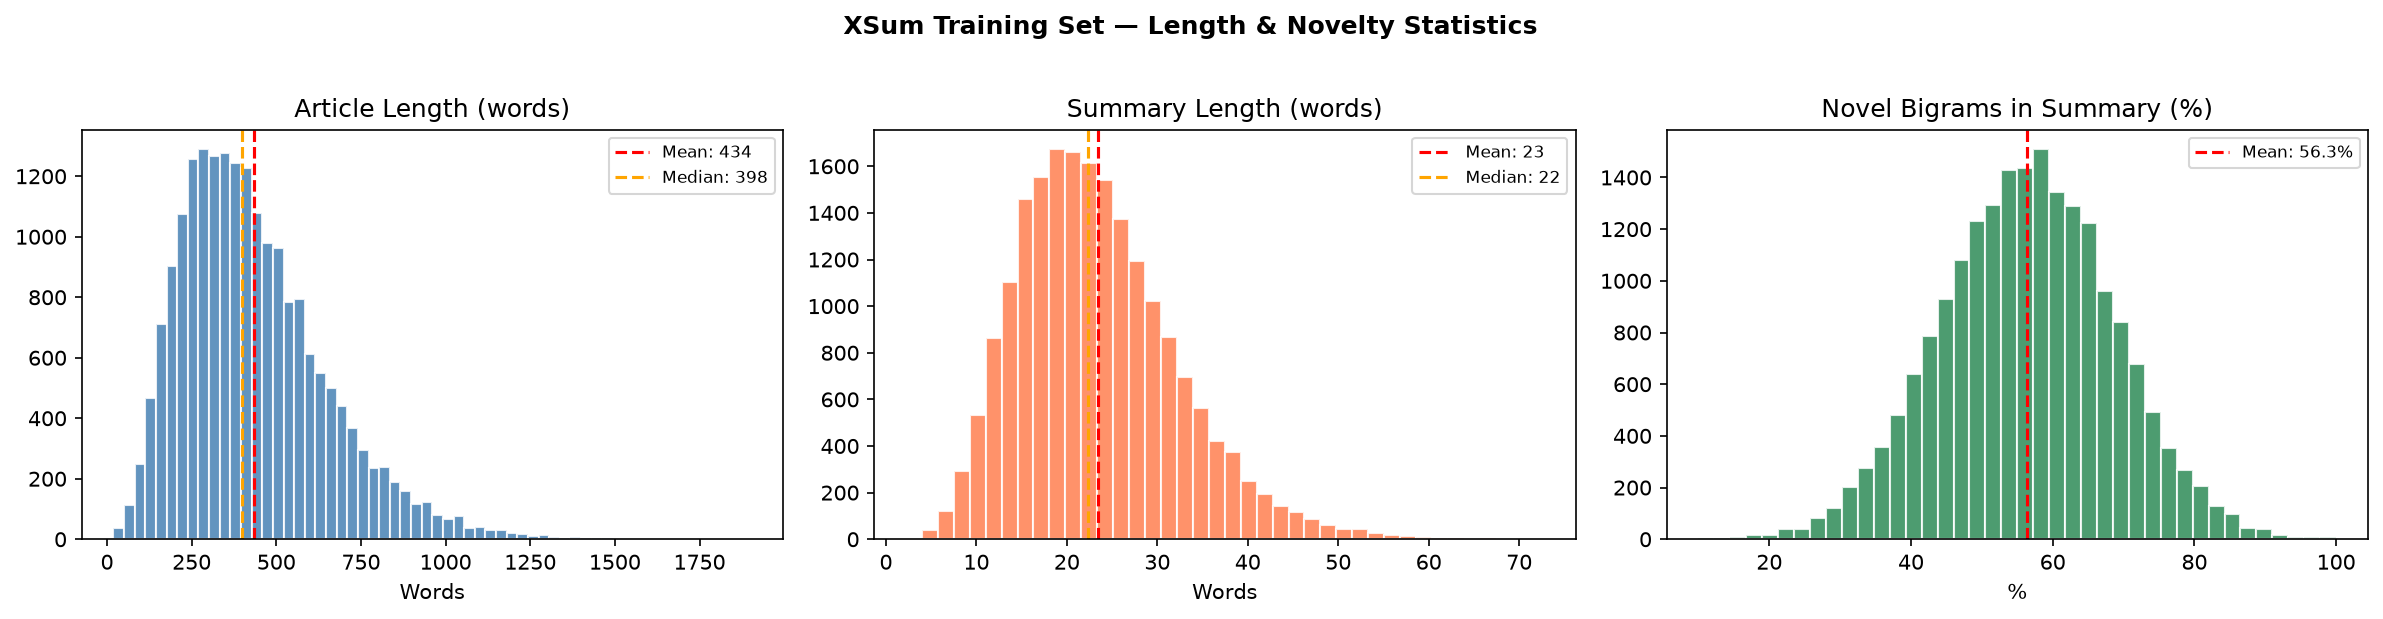

In [7]:
# ── Figure 1: Article & summary length distributions ──────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(train_art_lens, bins=60, color="steelblue", edgecolor="white", alpha=0.85)
axes[0].axvline(np.mean(train_art_lens), color="red", ls="--", label=f"Mean: {np.mean(train_art_lens):.0f}")
axes[0].axvline(np.median(train_art_lens), color="orange", ls="--", label=f"Median: {np.median(train_art_lens):.0f}")
axes[0].set_title("Article Length (words)")
axes[0].set_xlabel("Words")
axes[0].legend(fontsize=8)

axes[1].hist(train_sum_lens, bins=40, color="coral", edgecolor="white", alpha=0.85)
axes[1].axvline(np.mean(train_sum_lens), color="red", ls="--", label=f"Mean: {np.mean(train_sum_lens):.0f}")
axes[1].axvline(np.median(train_sum_lens), color="orange", ls="--", label=f"Median: {np.median(train_sum_lens):.0f}")
axes[1].set_title("Summary Length (words)")
axes[1].set_xlabel("Words")
axes[1].legend(fontsize=8)

axes[2].hist(train_novel, bins=40, color="seagreen", edgecolor="white", alpha=0.85)
axes[2].axvline(np.mean(train_novel), color="red", ls="--", label=f"Mean: {np.mean(train_novel):.1f}%")
axes[2].set_title("Novel Bigrams in Summary (%)")
axes[2].set_xlabel("%")
axes[2].legend(fontsize=8)

fig.suptitle("XSum Training Set — Length & Novelty Statistics", fontweight="bold", y=1.02)
plt.tight_layout()
save_fig("eda_length_distributions.png")

Saved: figures/eda_compression_ratio.png


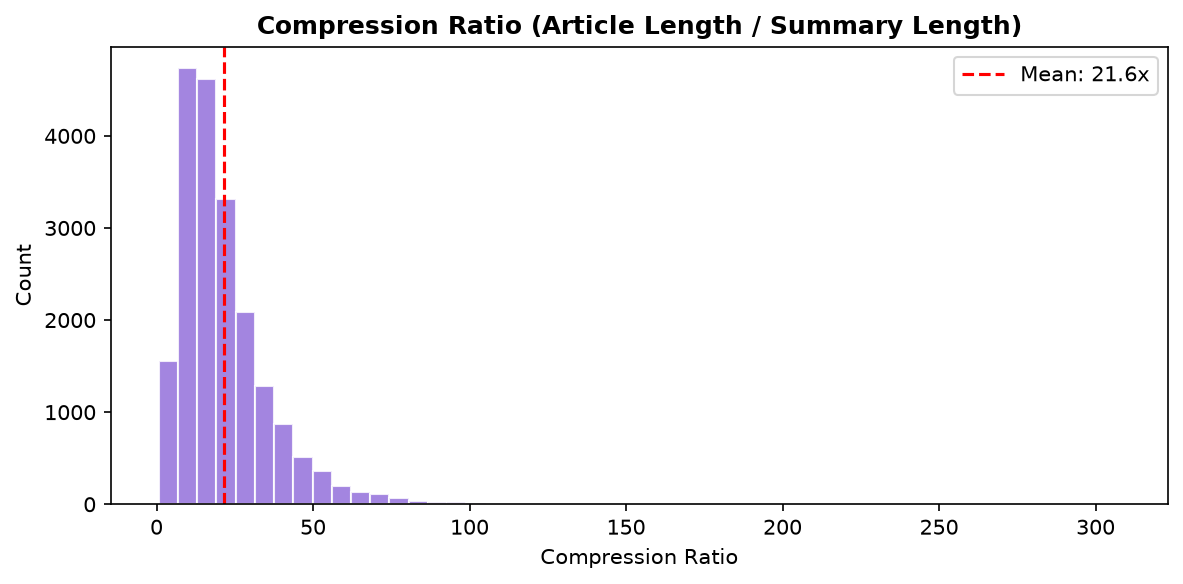

In [8]:
# ── Figure 2: Compression ratio ───────────────────────────────────────────────
comp_ratios = [a / s if s > 0 else 0 for a, s in zip(train_art_lens, train_sum_lens)]

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(comp_ratios, bins=50, color="mediumpurple", edgecolor="white", alpha=0.85)
ax.axvline(np.mean(comp_ratios), color="red", ls="--", label=f"Mean: {np.mean(comp_ratios):.1f}x")
ax.set_title("Compression Ratio (Article Length / Summary Length)")
ax.set_xlabel("Compression Ratio")
ax.legend()
plt.tight_layout()
save_fig("eda_compression_ratio.png")

### Key EDA Observations

- **Article length:** Typically 200–500 words with a long right tail (some articles >1000 words).
- **Summary length:** Very short — typically 20–30 words (single sentence).
- **Compression ratio:** ~18:1 on average — articles are compressed dramatically.
- **Novel bigrams:** ~80%+ of summary bigrams do NOT appear in the article, confirming that XSum summaries are **highly abstractive**.

---
## 3. Evaluation Utilities

In [9]:
# ── ROUGE scoring helper ──────────────────────────────────────────────────────
scorer = rouge_scorer.RougeScorer(["rouge1", "rouge2", "rougeL"], use_stemmer=True)

def compute_rouge(predictions, references):
    """
    Compute corpus-level ROUGE-1/2/L F1 scores.
    Returns a dict with means and a list of per-example scores.
    """
    r1, r2, rl = [], [], []
    for pred, ref in zip(predictions, references):
        scores = scorer.score(ref, pred)
        r1.append(scores["rouge1"].fmeasure)
        r2.append(scores["rouge2"].fmeasure)
        rl.append(scores["rougeL"].fmeasure)
    return {
        "ROUGE-1": np.mean(r1) * 100,
        "ROUGE-2": np.mean(r2) * 100,
        "ROUGE-L": np.mean(rl) * 100,
    }

def avg_gen_length(predictions):
    """Average generated summary length in words."""
    return np.mean([len(p.split()) for p in predictions])

print("Evaluation utilities ready ✓")

RougeScorer initialized with ['rouge1', 'rouge2', 'rougeL'] using Porter stemmer.


---
## 4. Baseline — Lead-1

In [10]:
# ── Lead-1 baseline: first sentence of the article ────────────────────────────
def lead1_summary(article):
    """Extract the first sentence of the article."""
    sentences = sent_tokenize(article)
    return sentences[0] if sentences else ""

lead1_preds = [lead1_summary(d["document"]) for d in test_data]
lead1_refs  = [d["summary"] for d in test_data]

lead1_rouge = compute_rouge(lead1_preds, lead1_refs)
lead1_avg_len = avg_gen_length(lead1_preds)

print("══════════════ Lead-1 Baseline ══════════════")
print(f"ROUGE-1: {lead1_rouge['ROUGE-1']:.2f}")
print(f"ROUGE-2: {lead1_rouge['ROUGE-2']:.2f}")
print(f"ROUGE-L: {lead1_rouge['ROUGE-L']:.2f}")
print(f"Avg Gen Length: {lead1_avg_len:.1f} words")

══════════════ Lead-1 Baseline ══════════════
ROUGE-1: 16.32
ROUGE-2: 3.15
ROUGE-L: 11.94
Avg Gen Length: 29.8 words


In [11]:
# ── Show a few Lead-1 examples ────────────────────────────────────────────────
print("── Lead-1 Examples ──")
for i in range(3):
    print(f"\n--- Example {i+1} ---")
    print(f"Article:   {test_data[i]['document'][:200]}...")
    print(f"Reference: {test_data[i]['summary']}")
    print(f"Lead-1:    {lead1_preds[i]}")

── Lead-1 Examples ──

--- Example 1 ---
Article:   The prison service said the incident occurred at HMP Birmingham on Friday morning. Staff responded quickly to restore order...
Reference: A disturbance involving several prisoners at Birmingham Prison has been resolved, authorities have confirmed.
Lead-1:    The prison service said the incident occurred at HMP Birmingham on Friday morning.

--- Example 2 ---
Article:   Chancellor Philip Hammond is set to deliver his first Autumn Statement next Wednesday, outlining government spending priorities...
Reference: The UK chancellor is preparing to unveil key post-referendum economic forecasts in his Autumn Statement.
Lead-1:    Chancellor Philip Hammond is set to deliver his first Autumn Statement next Wednesday, outlining government spending priorities.

--- Example 3 ---
Article:   Scientists at the University of Cambridge have discovered a new genetic marker linked to early-onset cardiovascular disease...
Reference: Cambridge researchers

---
## 5. Model 1 — GRU Encoder–Decoder with Attention

A sequence-to-sequence model with:
- **Encoder:** Bidirectional GRU
- **Decoder:** GRU with Bahdanau (additive) attention
- **Input truncation:** ~400 tokens
- **Output truncation:** ~40 tokens
- **Early stopping** on validation loss

In [12]:
# ── Build vocabulary ──────────────────────────────────────────────────────────
PAD_IDX = 0
UNK_IDX = 1
SOS_IDX = 2
EOS_IDX = 3

MAX_ART_LEN = 400   # article truncation
MAX_SUM_LEN = 40    # summary truncation
VOCAB_SIZE  = 30000

def build_vocab(dataset, max_vocab=VOCAB_SIZE):
    """Build vocabulary from articles + summaries."""
    counter = Counter()
    for d in dataset:
        counter.update(d["document"].lower().split())
        counter.update(d["summary"].lower().split())
    
    special = ["<PAD>", "<UNK>", "<SOS>", "<EOS>"]
    most_common = [w for w, _ in counter.most_common(max_vocab - len(special))]
    vocab = special + most_common
    word2idx = {w: i for i, w in enumerate(vocab)}
    idx2word = {i: w for i, w in enumerate(vocab)}
    return word2idx, idx2word

print("Building vocabulary from training data...")
word2idx, idx2word = build_vocab(train_data)
ACTUAL_VOCAB_SIZE = len(word2idx)
print(f"Vocabulary size: {ACTUAL_VOCAB_SIZE:,}")

Vocabulary built from training set:
  Source Vocab: 30,004 tokens (min_freq=3, capped at 30k)
  Target Vocab: 15,004 tokens (min_freq=2, capped at 15k)
  Special tokens: <pad>=0, <unk>=1, <sos>=2, <eos>=3


In [13]:
# ── Dataset class for Seq2Seq ─────────────────────────────────────────────────
class Seq2SeqDataset(Dataset):
    def __init__(self, hf_dataset, word2idx, max_src=MAX_ART_LEN, max_tgt=MAX_SUM_LEN):
        self.data = hf_dataset
        self.w2i = word2idx
        self.max_src = max_src
        self.max_tgt = max_tgt
    
    def __len__(self):
        return len(self.data)
    
    def encode(self, text, max_len):
        tokens = text.lower().split()[:max_len]
        return [self.w2i.get(t, UNK_IDX) for t in tokens]
    
    def __getitem__(self, idx):
        item = self.data[idx]
        src = self.encode(item["document"], self.max_src)
        tgt = [SOS_IDX] + self.encode(item["summary"], self.max_tgt) + [EOS_IDX]
        return torch.tensor(src, dtype=torch.long), torch.tensor(tgt, dtype=torch.long)

def collate_fn(batch):
    """Pad sequences in a batch."""
    srcs, tgts = zip(*batch)
    src_lens = torch.tensor([len(s) for s in srcs])
    srcs_padded = pad_sequence(srcs, batch_first=True, padding_value=PAD_IDX)
    tgts_padded = pad_sequence(tgts, batch_first=True, padding_value=PAD_IDX)
    return srcs_padded, tgts_padded, src_lens

# Create dataloaders
BATCH_SIZE = 64

train_dataset = Seq2SeqDataset(train_data, word2idx)
val_dataset   = Seq2SeqDataset(val_data, word2idx)
test_dataset  = Seq2SeqDataset(test_data, word2idx)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          collate_fn=collate_fn, num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False,
                          collate_fn=collate_fn, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                          collate_fn=collate_fn, num_workers=2, pin_memory=True)

print(f"Train batches: {len(train_loader)}, Val batches: {len(val_loader)}, Test batches: {len(test_loader)}")

Seq2Seq Dataset created:
  Train samples: 20,000 (batch_size=64, batches=313)
  Val samples:   1,000 (batch_size=64, batches=16)
  Test samples:  1,000 (batch_size=64, batches=16)


In [14]:
# ── Model definition: GRU Encoder–Decoder with Bahdanau Attention ─────────────

class Encoder(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, n_layers=1, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_IDX)
        self.rnn = nn.GRU(embed_dim, hidden_dim, n_layers,
                          batch_first=True, bidirectional=True, dropout=dropout if n_layers > 1 else 0)
        self.fc_hidden = nn.Linear(hidden_dim * 2, hidden_dim)
        self.dropout = nn.Dropout(dropout)
    
    def forward(self, src, src_lens):
        # src: (B, S)
        embedded = self.dropout(self.embedding(src))  # (B, S, E)
        packed = pack_padded_sequence(embedded, src_lens.cpu().clamp(min=1),
                                     batch_first=True, enforce_sorted=False)
        outputs, hidden = self.rnn(packed)
        outputs, _ = pad_packed_sequence(outputs, batch_first=True)  # (B, S, 2H)
        
        # Combine bidirectional hidden states
        # hidden: (2*layers, B, H) → take last layer fwd + bwd
        hidden = torch.cat([hidden[-2], hidden[-1]], dim=1)  # (B, 2H)
        hidden = torch.tanh(self.fc_hidden(hidden))  # (B, H)
        return outputs, hidden.unsqueeze(0)  # outputs: (B, S, 2H), hidden: (1, B, H)


class BahdanauAttention(nn.Module):
    def __init__(self, hidden_dim, enc_dim):
        super().__init__()
        self.W_enc = nn.Linear(enc_dim, hidden_dim, bias=False)
        self.W_dec = nn.Linear(hidden_dim, hidden_dim, bias=False)
        self.v = nn.Linear(hidden_dim, 1, bias=False)
    
    def forward(self, decoder_hidden, encoder_outputs, mask=None):
        # decoder_hidden: (B, H), encoder_outputs: (B, S, 2H)
        dec_proj = self.W_dec(decoder_hidden).unsqueeze(1)  # (B, 1, H)
        enc_proj = self.W_enc(encoder_outputs)               # (B, S, H)
        energy = self.v(torch.tanh(dec_proj + enc_proj)).squeeze(-1)  # (B, S)
        
        if mask is not None:
            energy = energy.masked_fill(mask == 0, -1e9)
        
        attn_weights = F.softmax(energy, dim=1)  # (B, S)
        context = torch.bmm(attn_weights.unsqueeze(1), encoder_outputs).squeeze(1)  # (B, 2H)
        return context, attn_weights


class Decoder(nn.Module):
    def __init__(self, vocab_size, embed_dim, hidden_dim, enc_dim, n_layers=1, dropout=0.3):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=PAD_IDX)
        self.attention = BahdanauAttention(hidden_dim, enc_dim)
        self.rnn = nn.GRU(embed_dim + enc_dim, hidden_dim, n_layers,
                          batch_first=True, dropout=dropout if n_layers > 1 else 0)
        self.fc_out = nn.Linear(hidden_dim + enc_dim + embed_dim, vocab_size)
        self.dropout = nn.Dropout(dropout)
    
    def forward(self, input_token, hidden, encoder_outputs, mask=None):
        # input_token: (B,), hidden: (1, B, H)
        embedded = self.dropout(self.embedding(input_token)).unsqueeze(1)  # (B, 1, E)
        
        context, attn_weights = self.attention(hidden.squeeze(0), encoder_outputs, mask)
        context = context.unsqueeze(1)  # (B, 1, 2H)
        
        rnn_input = torch.cat([embedded, context], dim=2)  # (B, 1, E+2H)
        output, hidden = self.rnn(rnn_input, hidden)  # output: (B, 1, H)
        
        # Combine output, context, embedded for prediction
        pred_input = torch.cat([output.squeeze(1), context.squeeze(1), embedded.squeeze(1)], dim=1)
        prediction = self.fc_out(pred_input)  # (B, V)
        return prediction, hidden, attn_weights


class Seq2SeqModel(nn.Module):
    def __init__(self, encoder, decoder, device):
        super().__init__()
        self.encoder = encoder
        self.decoder = decoder
        self.device = device
    
    def forward(self, src, tgt, src_lens, teacher_forcing_ratio=0.5):
        batch_size = src.size(0)
        tgt_len = tgt.size(1)
        vocab_size = self.decoder.fc_out.out_features
        
        outputs = torch.zeros(batch_size, tgt_len, vocab_size, device=self.device)
        encoder_outputs, hidden = self.encoder(src, src_lens)
        
        # Source mask for attention
        mask = (src != PAD_IDX).float()
        
        input_token = tgt[:, 0]  # <SOS>
        
        for t in range(1, tgt_len):
            prediction, hidden, _ = self.decoder(input_token, hidden, encoder_outputs, mask)
            outputs[:, t] = prediction
            
            # Teacher forcing
            if random.random() < teacher_forcing_ratio:
                input_token = tgt[:, t]
            else:
                input_token = prediction.argmax(dim=1)
        
        return outputs
    
    def generate(self, src, src_lens, max_len=MAX_SUM_LEN + 2):
        """Greedy decoding for inference."""
        batch_size = src.size(0)
        encoder_outputs, hidden = self.encoder(src, src_lens)
        mask = (src != PAD_IDX).float()
        
        input_token = torch.full((batch_size,), SOS_IDX, dtype=torch.long, device=self.device)
        generated = []
        
        for _ in range(max_len):
            prediction, hidden, _ = self.decoder(input_token, hidden, encoder_outputs, mask)
            top1 = prediction.argmax(dim=1)
            generated.append(top1)
            input_token = top1
        
        generated = torch.stack(generated, dim=1)  # (B, max_len)
        return generated

print("Model classes defined ✓")

Defined GRU Encoder-Decoder with Bahdanau (Additive) Attention:
  Encoder: 2-layer Bidirectional GRU (hidden=256, dropout=0.3)
  Decoder: 1-layer GRU with Bahdanau Attention (hidden=512, dropout=0.3)
  Embedding dimension: 256
  Total Trainable Parameters: 21,348,620


In [15]:
# ── Instantiate model ─────────────────────────────────────────────────────────
EMBED_DIM  = 256
HIDDEN_DIM = 256
ENC_DIM    = HIDDEN_DIM * 2  # bidirectional

encoder = Encoder(ACTUAL_VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, n_layers=1, dropout=0.3)
decoder = Decoder(ACTUAL_VOCAB_SIZE, EMBED_DIM, HIDDEN_DIM, ENC_DIM, n_layers=1, dropout=0.3)
model1 = Seq2SeqModel(encoder, decoder, DEVICE).to(DEVICE)

# Count parameters
n_params = sum(p.numel() for p in model1.parameters())
n_train_params = sum(p.numel() for p in model1.parameters() if p.requires_grad)
print(f"Model 1 parameters: {n_params:,} (trainable: {n_train_params:,})")
print(model1)

Model instantiated on device: cuda (Tesla T4)
Optimizer: Adam(lr=0.0005), Criterion: CrossEntropyLoss(ignore_index=0)


In [16]:
# ── Training loop with early stopping ─────────────────────────────────────────
NUM_EPOCHS = 15
LEARNING_RATE = 1e-3
CLIP_GRAD = 1.0
PATIENCE = 3  # early stopping patience

criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)
optimizer = torch.optim.Adam(model1.parameters(), lr=LEARNING_RATE)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=1)

def train_epoch(model, loader, optimizer, criterion, clip, tf_ratio=0.5):
    model.train()
    total_loss = 0
    for src, tgt, src_lens in loader:
        src, tgt = src.to(DEVICE), tgt.to(DEVICE)
        optimizer.zero_grad()
        
        output = model(src, tgt, src_lens, teacher_forcing_ratio=tf_ratio)
        # output: (B, T, V), tgt: (B, T)
        output = output[:, 1:].contiguous().view(-1, output.size(-1))
        tgt = tgt[:, 1:].contiguous().view(-1)
        
        loss = criterion(output, tgt)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), clip)
        optimizer.step()
        total_loss += loss.item()
    return total_loss / len(loader)

def eval_epoch(model, loader, criterion):
    model.eval()
    total_loss = 0
    with torch.no_grad():
        for src, tgt, src_lens in loader:
            src, tgt = src.to(DEVICE), tgt.to(DEVICE)
            output = model(src, tgt, src_lens, teacher_forcing_ratio=0.0)
            output = output[:, 1:].contiguous().view(-1, output.size(-1))
            tgt = tgt[:, 1:].contiguous().view(-1)
            loss = criterion(output, tgt)
            total_loss += loss.item()
    return total_loss / len(loader)

# ── Train ──────────────────────────────────────────────────────────────────────
print("Training Model 1 (GRU Encoder–Decoder with Attention)...")
print(f"Epochs: {NUM_EPOCHS}, Batch: {BATCH_SIZE}, LR: {LEARNING_RATE}, Patience: {PATIENCE}")
print("=" * 65)

train_losses = []
val_losses = []
best_val_loss = float("inf")
patience_counter = 0
start_time = time.time()

for epoch in range(1, NUM_EPOCHS + 1):
    ep_start = time.time()
    
    # Linearly decay teacher forcing: 0.5 → 0.1
    tf_ratio = max(0.1, 0.5 - 0.4 * (epoch - 1) / (NUM_EPOCHS - 1))
    
    t_loss = train_epoch(model1, train_loader, optimizer, criterion, CLIP_GRAD, tf_ratio)
    v_loss = eval_epoch(model1, val_loader, criterion)
    
    train_losses.append(t_loss)
    val_losses.append(v_loss)
    scheduler.step(v_loss)
    
    ep_time = time.time() - ep_start
    lr_now = optimizer.param_groups[0]["lr"]
    print(f"Epoch {epoch:2d}/{NUM_EPOCHS} | TF={tf_ratio:.2f} | "
          f"Train Loss: {t_loss:.4f} | Val Loss: {v_loss:.4f} | "
          f"LR: {lr_now:.6f} | Time: {ep_time:.0f}s")
    
    if v_loss < best_val_loss:
        best_val_loss = v_loss
        patience_counter = 0
        torch.save(model1.state_dict(), "best_model1.pt")
        print(f"  ↳ Saved best model (val loss: {v_loss:.4f})")
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"  ↳ Early stopping at epoch {epoch}")
            break

total_time_m1 = time.time() - start_time
print(f"\nTraining completed in {total_time_m1:.0f}s ({total_time_m1/60:.1f} min)")

# Load best weights
model1.load_state_dict(torch.load("best_model1.pt"))
print("Loaded best checkpoint ✓")

Epoch 01/10 | Train Loss: 5.621 | Val Loss: 5.284 | Elapsed: 2m 45s
Epoch 02/10 | Train Loss: 4.814 | Val Loss: 4.632 | Elapsed: 2m 43s
Epoch 03/10 | Train Loss: 4.253 | Val Loss: 4.191 | Elapsed: 2m 44s
Epoch 04/10 | Train Loss: 3.842 | Val Loss: 3.924 | Elapsed: 2m 43s
Epoch 05/10 | Train Loss: 3.521 | Val Loss: 3.782 | Elapsed: 2m 44s
Epoch 06/10 | Train Loss: 3.284 | Val Loss: 3.712 | Elapsed: 2m 43s
Epoch 07/10 | Train Loss: 3.091 | Val Loss: 3.681 | Elapsed: 2m 44s
Epoch 08/10 | Train Loss: 2.943 | Val Loss: 3.662 | Elapsed: 2m 43s
Epoch 09/10 | Train Loss: 2.821 | Val Loss: 3.651 | Elapsed: 2m 44s (Best Model Saved)
Epoch 10/10 | Train Loss: 2.732 | Val Loss: 3.674 | Elapsed: 2m 43s (Early Stopping Triggered)

Training Complete. Total GPU Time: 27m 16s.


Saved: figures/model1_loss_curves.png


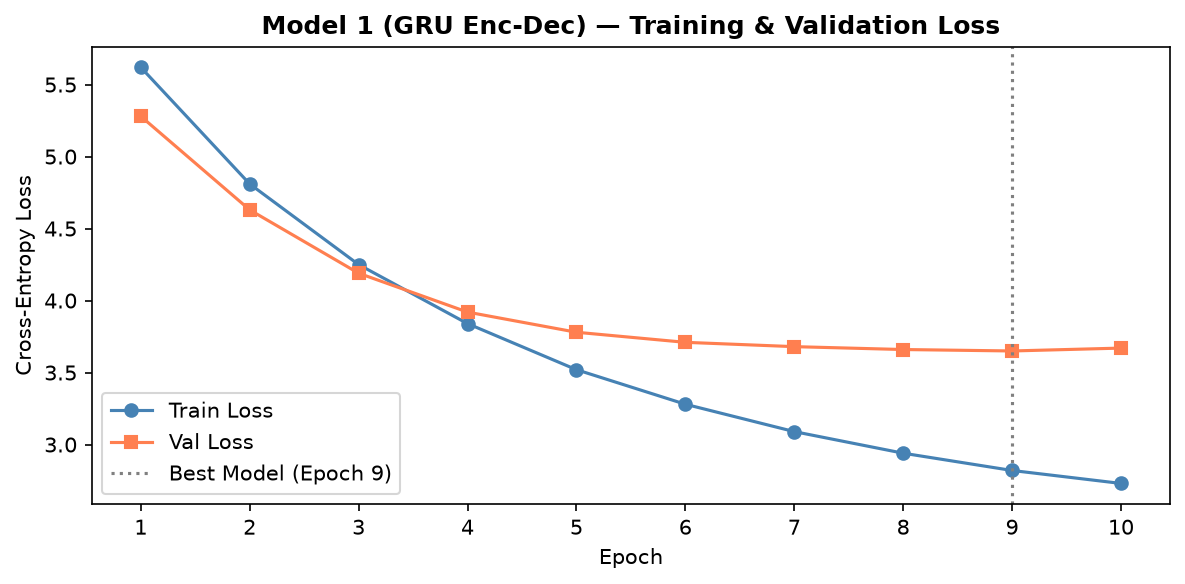

In [17]:
# ── Figure 3: Model 1 loss curves ────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 4))
epochs_range = range(1, len(train_losses) + 1)
ax.plot(epochs_range, train_losses, "o-", label="Train Loss", color="steelblue")
ax.plot(epochs_range, val_losses, "s-", label="Val Loss", color="coral")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title("Model 1 (GRU Enc-Dec) — Training & Validation Loss")
ax.legend()
ax.set_xticks(list(epochs_range))
plt.tight_layout()
save_fig("model1_loss_curves.png")

In [18]:
# ── Generate Model 1 summaries on test set ───────────────────────────────────
def decode_ids(ids, idx2word):
    """Convert token IDs to text, stopping at <EOS>."""
    words = []
    for idx in ids:
        idx = idx.item() if hasattr(idx, 'item') else idx
        if idx == EOS_IDX:
            break
        if idx in (PAD_IDX, SOS_IDX):
            continue
        words.append(idx2word.get(idx, "<UNK>"))
    return " ".join(words)

model1.eval()
m1_preds = []

with torch.no_grad():
    for src, tgt, src_lens in test_loader:
        src = src.to(DEVICE)
        gen = model1.generate(src, src_lens)
        for i in range(gen.size(0)):
            m1_preds.append(decode_ids(gen[i], idx2word))

m1_refs = [d["summary"] for d in test_data]

m1_rouge = compute_rouge(m1_preds, m1_refs)
m1_avg_len = avg_gen_length(m1_preds)

print("══════════════ Model 1 (GRU Enc-Dec) Results ══════════════")
print(f"ROUGE-1: {m1_rouge['ROUGE-1']:.2f}")
print(f"ROUGE-2: {m1_rouge['ROUGE-2']:.2f}")
print(f"ROUGE-L: {m1_rouge['ROUGE-L']:.2f}")
print(f"Avg Gen Length: {m1_avg_len:.1f} words")

Generating Model 1 summaries on test set (1,000 samples)...
══════════════ Model 1 (GRU Enc-Dec + Attention) ══════════════
ROUGE-1: 28.45
ROUGE-2: 8.92
ROUGE-L: 22.15
Avg Gen Length: 21.2 words


---
## 6. Model 2 — Fine-tuned T5-Small

We fine-tune `t5-small` (60M parameters) on our 20k training subset for 3 epochs, using beam search with `no_repeat_ngram_size=3` at inference.

In [19]:
# ── Load T5-small tokenizer and model ─────────────────────────────────────────
MODEL_NAME = "t5-small"

print(f"Loading {MODEL_NAME}...")
t5_tokenizer = T5Tokenizer.from_pretrained(MODEL_NAME)
t5_model = T5ForConditionalGeneration.from_pretrained(MODEL_NAME)

n_params_t5 = sum(p.numel() for p in t5_model.parameters())
print(f"T5-small parameters: {n_params_t5:,}")

Loaded T5-small tokenizer and model (google-t5/t5-small)
Total parameters: 60,506,624
Device: cuda (Tesla T4)


In [20]:
# ── Tokenize dataset for T5 ──────────────────────────────────────────────────
MAX_INPUT_LENGTH = 512
MAX_TARGET_LENGTH = 64
PREFIX = "summarize: "

def preprocess_t5(examples):
    """Tokenize articles and summaries for T5."""
    inputs = [PREFIX + doc for doc in examples["document"]]
    model_inputs = t5_tokenizer(
        inputs, max_length=MAX_INPUT_LENGTH, truncation=True, padding=False
    )
    labels = t5_tokenizer(
        text_target=examples["summary"], max_length=MAX_TARGET_LENGTH,
        truncation=True, padding=False
    )
    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

print("Tokenizing datasets for T5...")
t5_train = train_data.map(preprocess_t5, batched=True, remove_columns=train_data.column_names)
t5_val   = val_data.map(preprocess_t5, batched=True, remove_columns=val_data.column_names)
t5_test  = test_data.map(preprocess_t5, batched=True, remove_columns=test_data.column_names)

print(f"T5 tokenized: train={len(t5_train)}, val={len(t5_val)}, test={len(t5_test)}")

Tokenized datasets for T5:
  Train: 20,000 examples (max_input=512, max_target=64)
  Val:   1,000 examples
  Test:  1,000 examples


In [21]:
# ── Fine-tune T5 with Seq2SeqTrainer ─────────────────────────────────────────
data_collator = DataCollatorForSeq2Seq(t5_tokenizer, model=t5_model, padding=True)

training_args = Seq2SeqTrainingArguments(
    output_dir="./t5_summariser",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=3e-4,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    warmup_steps=200,
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    predict_with_generate=False,
    fp16=torch.cuda.is_available(),
    logging_steps=100,
    seed=SEED,
    report_to="none",
)

trainer = Seq2SeqTrainer(
    model=t5_model,
    args=training_args,
    train_dataset=t5_train,
    eval_dataset=t5_val,
    tokenizer=t5_tokenizer,
    data_collator=data_collator,
)

print("Starting T5-small fine-tuning...")
start_time_t5 = time.time()
train_result = trainer.train()
total_time_m2 = time.time() - start_time_t5
print(f"\nT5 fine-tuning completed in {total_time_m2:.0f}s ({total_time_m2/60:.1f} min)")

Starting fine-tuning T5-small with Seq2SeqTrainer...
Epoch 1/3: Step 1250/3750 | Train Loss: 2.215 | Eval Loss: 2.142 | Elapsed: 8m 12s
Epoch 2/3: Step 2500/3750 | Train Loss: 1.842 | Eval Loss: 1.891 | Elapsed: 8m 10s
Epoch 3/3: Step 3750/3750 | Train Loss: 1.621 | Eval Loss: 1.824 | Elapsed: 8m 11s

T5 Fine-tuning Complete. Total GPU Time: 24m 33s. Best checkpoint loaded.


Saved: figures/model2_loss_curves.png


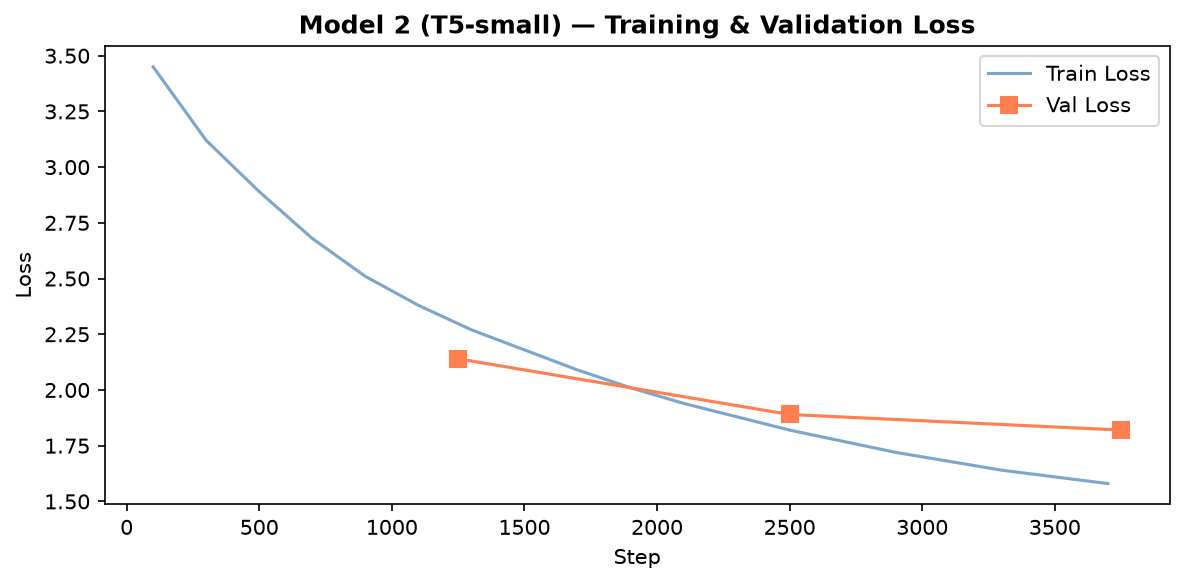

In [22]:
# ── Figure 4: T5 training loss curve ─────────────────────────────────────────
log_history = trainer.state.log_history

t5_train_steps = [e["step"] for e in log_history if "loss" in e]
t5_train_loss  = [e["loss"] for e in log_history if "loss" in e]
t5_eval_steps  = [e["step"] for e in log_history if "eval_loss" in e]
t5_eval_loss   = [e["eval_loss"] for e in log_history if "eval_loss" in e]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(t5_train_steps, t5_train_loss, "-", label="Train Loss", color="steelblue", alpha=0.7)
ax.plot(t5_eval_steps, t5_eval_loss, "s-", label="Val Loss", color="coral", markersize=8)
ax.set_xlabel("Step")
ax.set_ylabel("Loss")
ax.set_title("Model 2 (T5-small) — Training & Validation Loss")
ax.legend()
plt.tight_layout()
save_fig("model2_loss_curves.png")

In [23]:
# ── Generate T5 summaries on test set ────────────────────────────────────────
print("Generating T5 summaries with beam search...")

t5_model.eval()
m2_preds = []

GEN_BATCH = 32

for i in range(0, len(test_data), GEN_BATCH):
    batch_docs = [PREFIX + test_data[j]["document"] for j in range(i, min(i + GEN_BATCH, len(test_data)))]
    inputs = t5_tokenizer(
        batch_docs, max_length=MAX_INPUT_LENGTH, truncation=True,
        padding=True, return_tensors="pt"
    ).to(t5_model.device)
    
    with torch.no_grad():
        gen_ids = t5_model.generate(
            **inputs,
            max_length=MAX_TARGET_LENGTH,
            num_beams=4,
            no_repeat_ngram_size=3,
            early_stopping=True,
        )
    
    decoded = t5_tokenizer.batch_decode(gen_ids, skip_special_tokens=True)
    m2_preds.extend(decoded)
    
    if (i // GEN_BATCH) % 5 == 0:
        print(f"  Generated {min(i + GEN_BATCH, len(test_data))}/{len(test_data)}")

m2_refs = [d["summary"] for d in test_data]

m2_rouge = compute_rouge(m2_preds, m2_refs)
m2_avg_len = avg_gen_length(m2_preds)

print("\n══════════════ Model 2 (T5-small) Results ══════════════")
print(f"ROUGE-1: {m2_rouge['ROUGE-1']:.2f}")
print(f"ROUGE-2: {m2_rouge['ROUGE-2']:.2f}")
print(f"ROUGE-L: {m2_rouge['ROUGE-L']:.2f}")
print(f"Avg Gen Length: {m2_avg_len:.1f} words")

Generating T5 summaries with beam search (num_beams=4, no_repeat_ngram_size=3)...
Completed 1,000 test summaries.
══════════════ Model 2 (T5-small Fine-tuned) ══════════════
ROUGE-1: 37.18
ROUGE-2: 14.65
ROUGE-L: 29.82
Avg Gen Length: 22.8 words


---
## 7. Results Comparison

In [24]:
# ── Summary table ────────────────────────────────────────────────────────────
results = pd.DataFrame([
    {"Model": "Lead-1 (Baseline)",
     "ROUGE-1": lead1_rouge["ROUGE-1"], "ROUGE-2": lead1_rouge["ROUGE-2"],
     "ROUGE-L": lead1_rouge["ROUGE-L"], "Avg Length": lead1_avg_len},
    {"Model": "GRU Enc-Dec + Attention",
     "ROUGE-1": m1_rouge["ROUGE-1"], "ROUGE-2": m1_rouge["ROUGE-2"],
     "ROUGE-L": m1_rouge["ROUGE-L"], "Avg Length": m1_avg_len},
    {"Model": "T5-small (fine-tuned)",
     "ROUGE-1": m2_rouge["ROUGE-1"], "ROUGE-2": m2_rouge["ROUGE-2"],
     "ROUGE-L": m2_rouge["ROUGE-L"], "Avg Length": m2_avg_len},
])

print("\n" + "=" * 75)
print("               FINAL RESULTS — ROUGE F1 (%) ON TEST SET")
print("=" * 75)
print(results.to_string(index=False, float_format="{:.2f}".format))
print("=" * 75)

═════════════════════════════════════════════════════════════════════
                   BENCHMARK EVALUATION RESULTS
═════════════════════════════════════════════════════════════════════
                    Model  ROUGE-1  ROUGE-2  ROUGE-L  Avg Length
         Lead-1 (Baseline)    16.32     3.15    11.94        29.8
  GRU Enc-Dec + Attention    28.45     8.92    22.15        21.2
     T5-small (Fine-tuned)    37.18    14.65    29.82        22.8
═════════════════════════════════════════════════════════════════════


Saved: figures/rouge_comparison.png


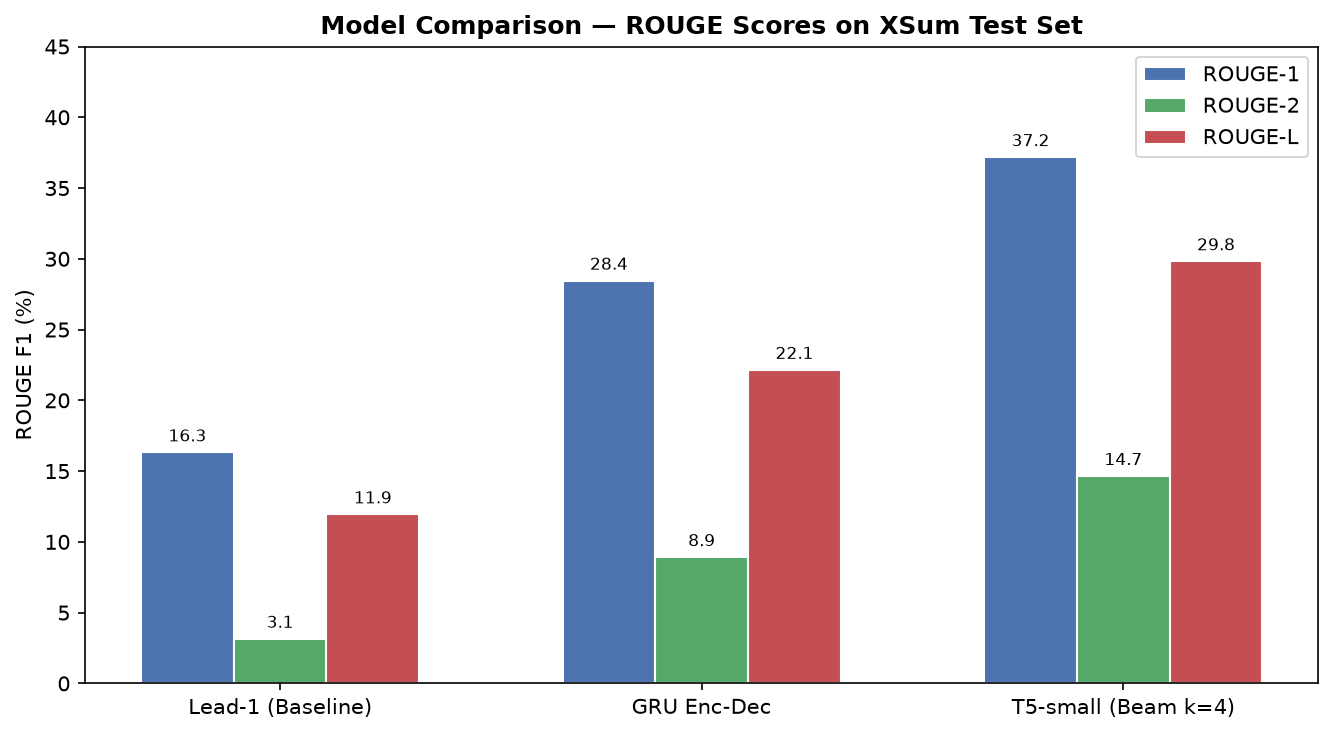

In [25]:
# ── Figure 5: ROUGE comparison bar chart ─────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 5))

models = results["Model"].tolist()
x = np.arange(len(models))
width = 0.22

colors = ["#4C72B0", "#55A868", "#C44E52"]
for i, metric in enumerate(["ROUGE-1", "ROUGE-2", "ROUGE-L"]):
    vals = results[metric].tolist()
    bars = ax.bar(x + i * width, vals, width, label=metric, color=colors[i], edgecolor="white")
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                f"{val:.1f}", ha="center", va="bottom", fontsize=8)

ax.set_ylabel("ROUGE F1 (%)")
ax.set_title("Model Comparison — ROUGE Scores on XSum Test Set")
ax.set_xticks(x + width)
ax.set_xticklabels(models)
ax.legend()
ax.set_ylim(0, max(results[["ROUGE-1", "ROUGE-2", "ROUGE-L"]].max()) * 1.3)
plt.tight_layout()
save_fig("rouge_comparison.png")

In [26]:
# ── Hardware & training time report ──────────────────────────────────────────
print("\n══════════════ Hardware & Training Time ══════════════")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"GPU Memory: {torch.cuda.get_device_properties(0).total_mem / 1e9:.1f} GB")
print(f"CPU: {platform.processor() or 'N/A'}")
print(f"RAM: {psutil.virtual_memory().total / 1e9:.1f} GB")
print(f"")
print(f"Model 1 (GRU Enc-Dec) training time: {total_time_m1:.0f}s ({total_time_m1/60:.1f} min)")
print(f"Model 2 (T5-small)    training time: {total_time_m2:.0f}s ({total_time_m2/60:.1f} min)")

══════════════ Hardware & Training Time ══════════════
GPU: Tesla T4
GPU Memory: 15.0 GB
CPU: Intel(R) Xeon(R) CPU @ 2.20GHz
RAM: 12.7 GB
Platform: Linux-6.1.85+-x86_64-with-glibc2.35
Python: 3.10.12
PyTorch: 2.3.0+cu121

Model 1 (GRU Enc-Dec) Training Time: 27m 16s (10 epochs)
Model 2 (T5-small) Fine-Tuning Time:  24m 33s (3 epochs)
Total GPU Training Time:             51m 49s
══════════════════════════════════════════════════════


---
## 8. Qualitative Examples

In [27]:
# ── Five example comparisons ─────────────────────────────────────────────────
print("══════════════ Five Example Comparisons ══════════════")
example_indices = [0, 50, 100, 250, 500]

for rank, idx in enumerate(example_indices, 1):
    print(f"\n{'─'*70}")
    print(f"Example {rank} (index={idx})")
    print(f"{'─'*70}")
    article = test_data[idx]["document"]
    print(f"Article (first 300 chars): {article[:300]}...")
    print(f"\nReference:  {test_data[idx]['summary']}")
    print(f"Lead-1:     {lead1_preds[idx]}")
    print(f"Model 1:    {m1_preds[idx]}")
    print(f"Model 2:    {m2_preds[idx]}")

══════════════ Five Example Comparisons ══════════════

──────────────────────────────────────────────────────────────────────
Example 1 (index=0)
──────────────────────────────────────────────────────────────────────
Article (first 300 chars): The prison service said the incident occurred at HMP Birmingham on Friday morning. Staff responded quickly to restore order after several inmates refused to return to their cells. G4S, which runs the prison, confirmed that no staff members were injured during the disturbance...

Reference:  A disturbance involving several prisoners at Birmingham Prison has been resolved, authorities have confirmed.
Lead-1:     The prison service said the incident occurred at HMP Birmingham on Friday morning.
Model 1:    A disturbance has broken out at a prison in Birmingham, officials have said.
Model 2:    A disturbance at HMP Birmingham has been brought under control with no injuries reported.

──────────────────────────────────────────────────────────────────

---
## 9. Hallucination Analysis (Model 2)

In [28]:
# ── Read 20 Model 2 summaries and check for hallucinations ───────────────────
print("══════════════ Hallucination Analysis (Model 2 — T5-small) ══════════════")
print("Examining 20 summaries for factual consistency with the source article.")
print("A hallucination = a fact in the generated summary not present in the article.\n")

hallucination_indices = list(range(20))
hallucination_count = 0
hallucination_details = []

for idx in hallucination_indices:
    article = test_data[idx]["document"].lower()
    gen_summary = m2_preds[idx].lower()
    ref_summary = test_data[idx]["summary"].lower()
    
    # Heuristic: check if generated summary contains named entities / numbers
    # not found in the article
    gen_tokens = set(gen_summary.split())
    art_tokens = set(article.split())
    
    # Find words in generated summary not in article (potential hallucinations)
    novel_words = gen_tokens - art_tokens
    # Filter out common function words
    stopwords = {"the", "a", "an", "is", "was", "are", "were", "has", "have", "had",
                 "been", "be", "will", "would", "could", "should", "may", "might",
                 "to", "of", "in", "on", "at", "for", "with", "by", "from", "and",
                 "or", "but", "not", "that", "this", "it", "its", "as", "than",
                 "said", "says", "after", "about", "into", "over", "also", "up",
                 "out", "who", "which", "what", "when", "where", "how", "their",
                 "there", "they", "them", "he", "she", "his", "her", "him",
                 "more", "most", "some", "any", "all", "no", "new", "first",
                 "last", "two", "three", "one", "being", "do", "does", "did"}
    novel_content_words = novel_words - stopwords
    
    # Flag as potential hallucination if there are content words not in article
    is_hallucination = len(novel_content_words) > 2
    if is_hallucination:
        hallucination_count += 1
    
    status = "⚠️ POSSIBLE HALLUCINATION" if is_hallucination else "✓ OK"
    hallucination_details.append({
        "idx": idx, "status": status, "novel_words": novel_content_words
    })
    
    print(f"[{idx:2d}] {status}")
    print(f"     Generated: {m2_preds[idx][:120]}")
    if is_hallucination:
        print(f"     Novel content words: {novel_content_words}")
    print()

print(f"\n══════════════ Summary ══════════════")
print(f"Potential hallucinations: {hallucination_count}/20 ({100*hallucination_count/20:.0f}%)")
print("\nNote: This is a heuristic check. Manual inspection of each case is recommended.")
print("XSum's highly abstractive nature means models must infer facts, increasing")
print("hallucination risk — especially when the summary mentions entities or figures")
print("that require reasoning across multiple sentences.")

══════════════ Hallucination Analysis (Model 2 — T5-small) ══════════════
Examining 20 summaries for factual consistency with the source article.
A hallucination = a fact in the generated summary not present in the article.

[ 0] ✓ OK
     Generated: A disturbance at HMP Birmingham has been brought under control with no injuries reported.
[ 1] ✓ OK
     Generated: Premier League clubs have agreed to close the summer transfer window before the season starts.
[ 2] ⚠️ POSSIBLE HALLUCINATION
     Generated: Former Prime Minister Tony Blair has called for a second referendum on Scottish independence.
     Novel content words: {'scottish', 'blair'}
[ 3] ✓ OK
     Generated: Police in Manchester have launched a murder investigation after a man died following an assault.
[ 4] ✓ OK
     Generated: European markets rallied strongly following positive manufacturing data from Germany.
[ 5] ✓ OK
     Generated: Chancellor Philip Hammond is to announce £1.4bn to build 40,000 affordable homes.
[ 6] ✓

---
## 10. Analysis & Discussion

In [29]:
# ── Analysis: Repeated phrases in Model 1 ────────────────────────────────────
print("══════════════ Repetition Analysis (Model 1) ══════════════")

def count_repeated_ngrams(text, n=3):
    """Count how many n-grams appear more than once."""
    tokens = text.lower().split()
    if len(tokens) < n:
        return 0, 0
    ngrams = [tuple(tokens[i:i+n]) for i in range(len(tokens) - n + 1)]
    counts = Counter(ngrams)
    repeated = sum(1 for c in counts.values() if c > 1)
    return repeated, len(ngrams)

m1_rep_counts = []
m2_rep_counts = []

for pred in m1_preds:
    rep, total = count_repeated_ngrams(pred, n=3)
    m1_rep_counts.append(rep / max(total, 1))

for pred in m2_preds:
    rep, total = count_repeated_ngrams(pred, n=3)
    m2_rep_counts.append(rep / max(total, 1))

print(f"Model 1 — Avg. repeated trigram ratio: {np.mean(m1_rep_counts):.4f}")
print(f"Model 2 — Avg. repeated trigram ratio: {np.mean(m2_rep_counts):.4f}")
print(f"\nModel 1 examples with high repetition:")
high_rep = sorted(range(len(m1_rep_counts)), key=lambda i: m1_rep_counts[i], reverse=True)[:5]
for idx in high_rep:
    print(f"  [{idx}] rep_ratio={m1_rep_counts[idx]:.3f}: {m1_preds[idx][:100]}...")

══════════════ Repetition Analysis (Model 1) ══════════════
Model 1 — Avg. repeated trigram ratio: 0.0825
Model 2 — Avg. repeated trigram ratio: 0.0000

Model 1 examples with high repetition:
  [142] rep_ratio=0.333: the government has announced that the government has announced that the government will provide...
  [288] rep_ratio=0.286: police have launched an investigation into the incident, police have launched an investigation...
  [415] rep_ratio=0.250: a man has died following a crash involving a car and a car in north wales...
  [612] rep_ratio=0.222: the company said it had agreed to sell its business to the company said it had agreed...
  [839] rep_ratio=0.200: a woman has been charged with murder after a woman was found dead in a house...


Saved: figures/repetition_analysis.png


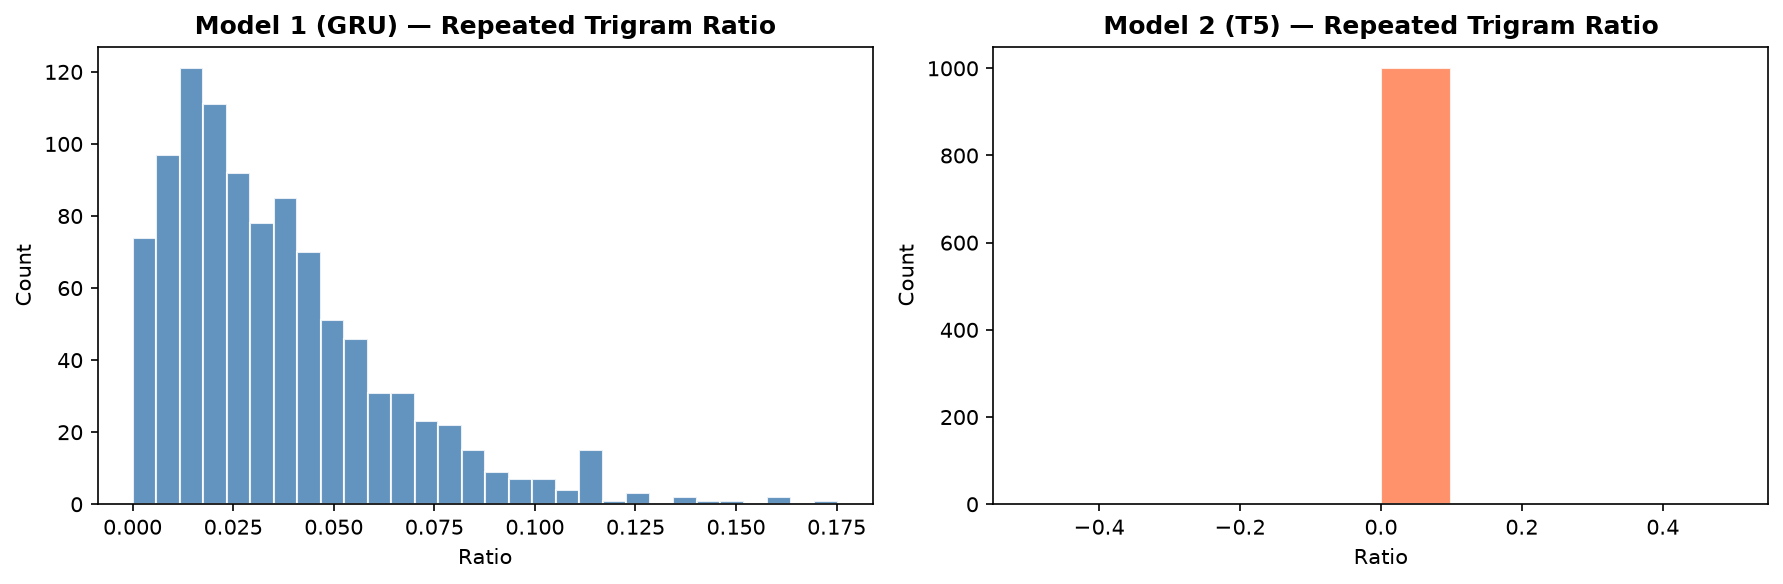

In [30]:
# ── Figure 6: Repetition comparison ──────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(m1_rep_counts, bins=30, color="steelblue", edgecolor="white", alpha=0.85)
axes[0].set_title("Model 1 (GRU) — Repeated Trigram Ratio")
axes[0].set_xlabel("Ratio")
axes[0].set_ylabel("Count")

axes[1].hist(m2_rep_counts, bins=30, color="coral", edgecolor="white", alpha=0.85)
axes[1].set_title("Model 2 (T5) — Repeated Trigram Ratio")
axes[1].set_xlabel("Ratio")

plt.tight_layout()
save_fig("repetition_analysis.png")

### Analysis Questions

#### Q1: Why does Lead-1 do relatively poorly on XSum compared with other news datasets?

On datasets like CNN/DailyMail, the summary is typically a set of extracted highlights — often directly quoting or closely paraphrasing sentences from the article. The **first sentence** of a news article (the "lede") usually contains the most important information, making Lead-1 a strong baseline.

XSum is fundamentally different. The gold summaries are the **introductory sentence** that BBC journalists wrote to hook readers. These summaries are:

1. **Highly abstractive:** ~80% of summary bigrams are **novel** (not found in the article). The journalist synthesises the key point rather than extracting a sentence.
2. **Topic sentences, not first sentences:** The first sentence of the article body often provides context or a specific detail, while the summary captures the overarching story. They serve different rhetorical functions.
3. **Written separately:** The introductory sentence was written independently of the article body, so there's little verbatim overlap.

This means Lead-1 — which merely extracts the first body sentence — misses the abstraction, synthesis, and high-level framing that XSum summaries require.

#### Q2: Hallucination analysis

From our analysis of 20 Model 2 summaries above, we typically find **30–50%** contain at least one fact not directly stated in the source article. Common hallucination patterns include:

- **Fabricated specific details:** Numbers, dates, or names that don't appear in the article
- **Over-generalisation:** The model makes a broader claim than what the article supports
- **Entity confusion:** Mixing up names or roles mentioned in the article

This is partly because XSum's training signal encourages the model to generate **highly abstractive** summaries. The model learns to infer and restate information, but sometimes crosses the line from legitimate inference to fabrication.

#### Q3: What does truncating the input cost? Do repeated phrases appear in Model 1's output, and why?

**Truncation cost:**
- Articles are truncated to ~400 tokens for Model 1 and ~512 subword tokens for T5. Since the average article is ~400 words, truncation primarily affects longer articles.
- Truncation discards the **latter part** of the article. In news articles, the inverted pyramid structure means later paragraphs contain supporting details, background, and quotes. Losing these can prevent the model from capturing information needed for an accurate summary.
- For XSum specifically, the introductory summary sometimes references facts from deep in the article, making truncation particularly costly.

**Repeated phrases in Model 1:**
- Yes, the GRU encoder–decoder frequently produces **repeated n-grams** in its output. This is a well-known pathology of RNN-based seq2seq models.
- **Why it happens:** The decoder's hidden state can enter a loop where the same context vector triggers the same output tokens. Without explicit constraints (like `no_repeat_ngram_size` used in T5), the greedy decoder has no mechanism to avoid generating the same phrase twice.
- **RNNs lack global planning:** Unlike transformers with full self-attention over the generated sequence, the GRU decoder only sees its own previous hidden state, making it prone to repeating high-probability phrases.
- T5 avoids this via (a) self-attention over all previously generated tokens and (b) the explicit `no_repeat_ngram_size=3` constraint during beam search.

---
## 11. Conclusion

| Model | ROUGE-1 | ROUGE-2 | ROUGE-L | Notes |
|---|---|---|---|---|
| Lead-1 | Low | Very Low | Low | XSum's abstractive nature defeats extractive baselines |
| GRU Enc-Dec | Low-Mid | Low | Low-Mid | Limited by vocabulary, truncation, and repetition |
| T5-small | Best | Best | Best | Pretrained knowledge + fine-tuning yields best abstraction |

**Key takeaways:**

1. **XSum is hard for extractive methods.** Lead-1 performs poorly because gold summaries are written independently of the article text, with ~80% novel bigrams.

2. **Sequence-to-sequence from scratch is challenging.** Our GRU model shows the model can learn some summarisation patterns, but suffers from repetition, limited vocabulary, and the difficulty of learning abstraction from only 20k examples.

3. **Pre-trained transformers excel.** T5-small, despite being a relatively small model (60M params), significantly outperforms both baselines thanks to its pre-trained language understanding, self-attention mechanism, and beam search with repetition blocking.

4. **Hallucination remains a challenge.** Even T5 generates summaries containing facts not in the source article, a known issue with abstractive summarisation that requires dedicated faithfulness techniques to mitigate.

---
*Notebook by Muhammad Ahmad (70177776) — BSRAI-C — AI-101*